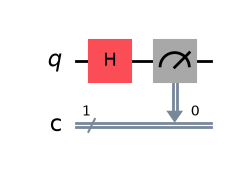

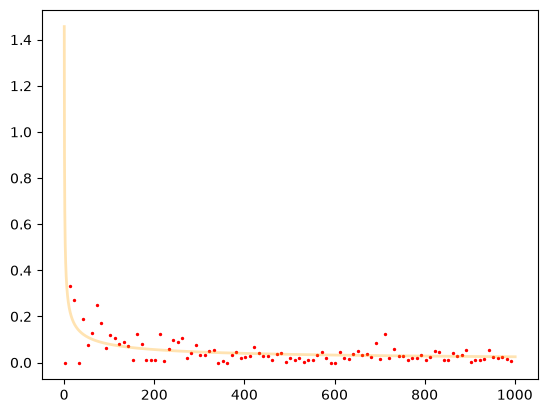

In [4]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt
from qiskit.visualization import circuit_drawer

# Creo il circuito, inserisco le informazioni sul funzionamento del circuito
# Comando creazione circuito -> QuantumCircuit(numero qbit, numero cbit)
qc = QuantumCircuit(1,1)
# Applico l'operazione di Hadamard al qubit 0, il qubit si trova ora nel plus state
qc.h(0)
# Il qubit viene misurato e il risultato salvato nel cbit 0
qc.measure(0,0)


# Creo due array per salvare le coordinate x,y dei punti
y = np.array([])
x = np.array([])

#creo l'ambiente di simulazione
simulator = AerSimulator()



# Creo ora un ciclo for
# A ogni ripetizione del ciclo, il circuito viene avviato per i volte 
# Si salva invfine la differenza di numero tra gli 0 misura e gli 1 misurati fratto i
# Si rappresenta la differenza relativa di misurazione in funzione di i 
for i in range(2, 1001, 10):
    # Avvia il circuito per i volte
    job = simulator.run(qc, shots = i)
    #Estraggo l'oggetto contenente le informazioni grezze sull'esperimento completato
    result= job.result()
    # Analizzo le misurazioni dell'esperimento e le organizzo in un dizionario Python
    counts = result.get_counts()
    #conteggio il numero di 1  e 0
    n_0 = counts.get('0', 0)
    n_1 = counts.get('1', 0)


    # Aggiungo alla lista il modulo della differenza relativa
    y = np.append(y, (abs(n_0 - n_1)/i)) 
    x = np.append(x, i)


# Creo la curva teorica
# Creo le x della curva teorica
shots_list = np.arange(0.3, 1001, 0.1)
# Associo le x alle y corrispondenti
curva_teorica = np.sqrt(2 / (np.pi * shots_list))
plt.plot(shots_list, curva_teorica, color='orange', linewidth=2, linestyle='-', alpha=0.3, label=r'Andamento teorico $\sqrt{2/(\pi N)}$')
plt.scatter(x, y, color ='red', s=2)

# Rappresento il circuito graficamento
qc.draw('mpl')

